In [ ]:
# Load and split the leaf dataset

import os
import zipfile
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import drive
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.metrics import confusion_matrix, classification_report

drive.mount("/content/drive")

ZIP_PATH = "/content/drive/MyDrive/leaf_dataset/dataset.zip"
DATA_DIR = "/content/leaf_dataset"

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 30
SEED = 42

if not os.path.exists(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(DATA_DIR)

dataset_dir = DATA_DIR

if len(os.listdir(dataset_dir)) == 1:
    folder = os.path.join(dataset_dir, os.listdir(dataset_dir)[0])
    if os.path.isdir(folder):
        dataset_dir = folder

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

class_names = train_ds.class_names

n = tf.data.experimental.cardinality(temp_ds)
half = n // 2

val_ds = temp_ds.take(half)
test_ds = temp_ds.skip(half)

print("Classes:", class_names)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 4948 files belonging to 2 classes.
Using 3464 files for training.
Found 4948 files belonging to 2 classes.
Using 1484 files for validation.
Classes: ['aam_pata', 'kathal_pata']


In [ ]:
# Prepare efficient datasets with data augmentation

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

augmentation = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomFlip("horizontal")
])

def augment(x, y):
    return augmentation(x, training=True), y

train_aug = train_ds.map(
    augment,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

In [ ]:
# Build and fine-tune the MobileNetV2 transfer learning model

base = MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base.trainable = True

for layer in base.layers[:-30]:
    layer.trainable = False

model = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    layers.Lambda(preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda_1 (Lambda)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 1,690,497 (6.45 MB)

 Non-trainable params: 731,584 (2.79 MB)

In [ ]:
# Train the transfer learning model

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_aug,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 53s 315ms/step - accuracy: 0.6810 - loss: 0.6145 - val_accuracy: 0.8478 - val_loss: 0.3959 - learning_rate: 1.0000e-05
Epoch 2/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 47s 93ms/step - accuracy: 0.8788 - loss: 0.3293 - val_accuracy: 0.9022 - val_loss: 0.2563 - learning_rate: 1.0000e-05
Epoch 3/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.9252 - loss: 0.2252 - val_accuracy: 0.9334 - val_loss: 0.1760 - learning_rate: 1.0000e-05
Epoch 4/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 12s 106ms/step - accuracy: 0.9469 - loss: 0.1722 - val_accuracy: 0.9470 - val_loss: 0.1373 - learning_rate: 1.0000e-05
Epoch 5/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 19s 96ms/step - accuracy: 0.9570 - loss: 0.1393 - val_accuracy: 0.9524 - val_loss: 0.1164 - learning_rate: 1.0000e-05
Epoch 6/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 10s 91ms/step - accuracy: 0.9651 - loss: 0.1178 - val_accuracy: 0.9565 - val_loss: 0.0962 - learning_rate: 1.0000e-05
Epoch 7/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/

In [ ]:
# Evaluate training, validation and test performance

train_loss, train_acc = model.evaluate(train_ds, verbose=0)
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Train Loss: {train_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Train Accuracy: 0.9986
Train Loss: 0.0089
Validation Accuracy: 0.9918
Validation Loss: 0.0178
Test Accuracy: 0.9840
Test Loss: 0.0598


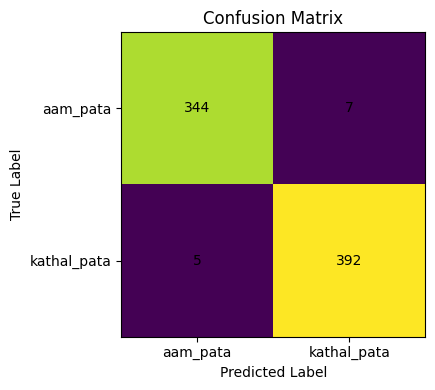

In [ ]:
# Generate and plot the confusion matrix

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy().ravel())
    y_pred.extend((predictions >= 0.5).astype(int).ravel())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0, 1], class_names)
plt.yticks([0, 1], class_names)

for i in range(2):
    for j in range(2):
        plt.text(
            j, i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [ ]:
# Generate precision, recall and F1-score

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

    aam_pata       0.99      0.98      0.98       351
 kathal_pata       0.98      0.99      0.98       397

    accuracy                           0.98       748
   macro avg       0.98      0.98      0.98       748
weighted avg       0.98      0.98      0.98       748



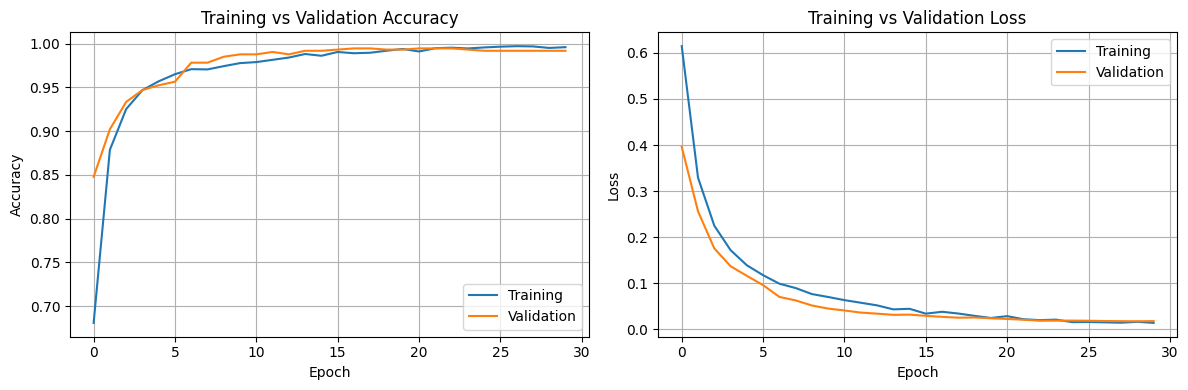

In [ ]:
# Plot training and validation performance

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training"
)

plt.plot(
    history.history["val_loss"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()